<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/PCVK_Ganjil_2026-2027_FadhilTaufiqurrachman/blob/main/Week5PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 5 - Histogram, Histogram Equalization, dan Dithering

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pengolahan Citra Dan Visi Komputer

**Sel Identitas Dan Parameter Pribadi**

In [1]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Fadhil Taufiqurrachman'
NIM  = '244107020090'

N     = int(NIM[-3:])
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s : %s' % (k, v))
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Fadhil Taufiqurrachman
NIM    : 244107020090 | N = 90
bins   : 32
clip   : 1.0
tile   : 4
L      : 2
WAKTU  : 2026-09-28 20:58:57 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : f604ddc9e5af02c0


In [2]:
# Connect To Google Drive For Image
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /PCVK Image/'

Mounted at /content/drive


### E1 - Percobaan Histogram

In [3]:
# Import Library
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

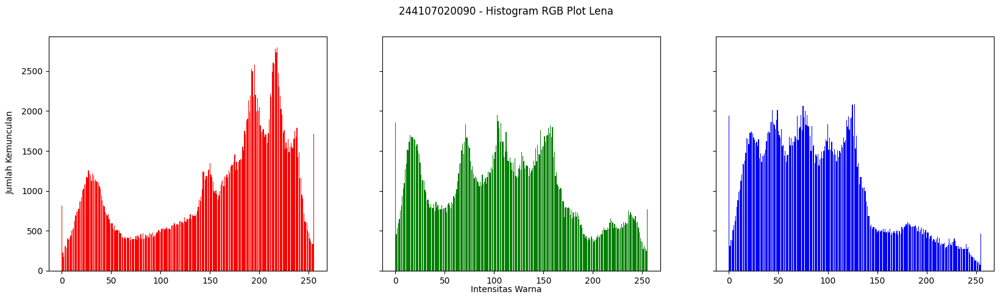

In [4]:
# Membuat Histogram Image (Manual) Tahap 1 Menggunakan Citra Contoh
img = cv.imread(BASE_PATH + 'lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Mengambil Dimensi Citra
height, width, depth = np.shape(img)
red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)

fig.suptitle('244107020090 - Histogram RGB Plot Lena')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

# Memasukkan Data Ke Dalam Masing-Masing Chart
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

# Menampilkan Grafik
plt.show()

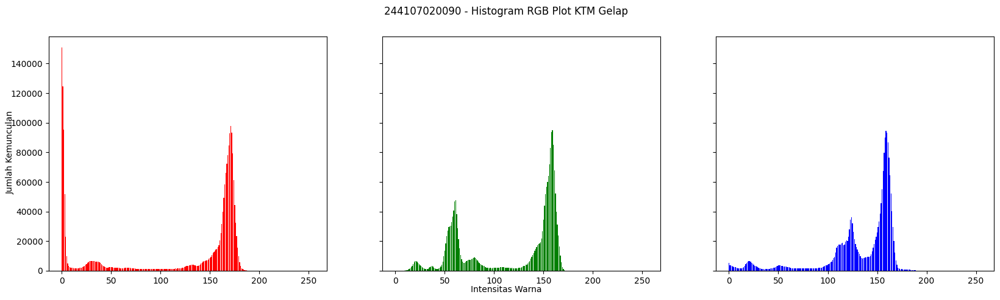

In [5]:
# Membuat Histogram Image (Manual) Tahap 1 Menggunakan Citra KTM Gelap
img = cv.imread(BASE_PATH + 'KTM1b.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Mengambil Dimensi Citra
height, width, depth = np.shape(img)
red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)

fig.suptitle('244107020090 - Histogram RGB Plot KTM Gelap')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

# Memasukkan Data Ke Dalam Masing-Masing Chart
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

plt.show()

Histogram citra lena.jpg menampilkan pembagian intensitas warna yang lebih tersebar luas di seluruh rentang pada ketiga channel RGB-nya. Hal ini artinya citra merepresentasikan variasi warna yang banyak, pencahayaan sesuai, dan kontras yang baik. Sebaliknya, histogram citra KTM menunjukkan grafik yang sangat sempit dengan puncak yang ekstrem di titik-titik tertentu saja. Terlihat pada penumpukan piksel di area mendekati 0. Karakteristik penumpukan ini disebabkan karena citra didominasi oleh area dengan warna solid yang seragam dan memiliki rentang kontras yang rendah akibat kondisi pencahayaan lampu ruangan yang tidak cukup baik.

**Pertanyaan Praktikum E1**

1. Perbandingan Manual, Numpy, Dan cv.calcHist

In [6]:
# Mendefinisikan Fungsi Manual Untuk 1 Channel (Grayscale)
def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1
    return h

def bandingkan_histogram(nama_file):
    img = cv.imread(BASE_PATH + nama_file, cv.IMREAD_GRAYSCALE)

    # 1. Menghitung Histogram Menggunakan Cara Manual
    hist_manual = histogram_manual(img)

    # 2. Menghitung Histogram Menggunakan Bawaan Library NumPy
    hist_np, _ = np.histogram(img.flatten(), 256, [0, 256])

    # 3. Menghitung Histogram Menggunakan Bawaan OpenCV
    hist_cv = cv.calcHist([img], [0], None, [256], [0, 256]).flatten()

    # Menghitung Selisih Maksimum Antara Hasil Manual Dengan NumPy Dan OpenCV
    selisih_np = np.max(np.abs(hist_manual - hist_np))
    selisih_cv = np.max(np.abs(hist_manual - hist_cv))

    print(f"--- Hasil Pembuktian Pada Citra {nama_file} ---")
    print(f"Selisih Maksimum Manual Vs NumPy  : {selisih_np}")
    print(f"Selisih Maksimum Manual Vs OpenCV : {selisih_cv}\n")

bandingkan_histogram('lena.jpg')
bandingkan_histogram('KTM1b.jpg')

--- Hasil Pembuktian Pada Citra lena.jpg ---
Selisih Maksimum Manual Vs NumPy  : 0
Selisih Maksimum Manual Vs OpenCV : 0.0

--- Hasil Pembuktian Pada Citra KTM1b.jpg ---
Selisih Maksimum Manual Vs NumPy  : 0
Selisih Maksimum Manual Vs OpenCV : 0.0



Hasil tersebut membuktikan bahwa dengan menggunakan cara manual dan otomatis menggunakan library tidak akan mengubah hasil histogram. Histogram akan sama persis selama rumus cara manual benar.

2. Kurva CDF (Cumulative Distribution Function)

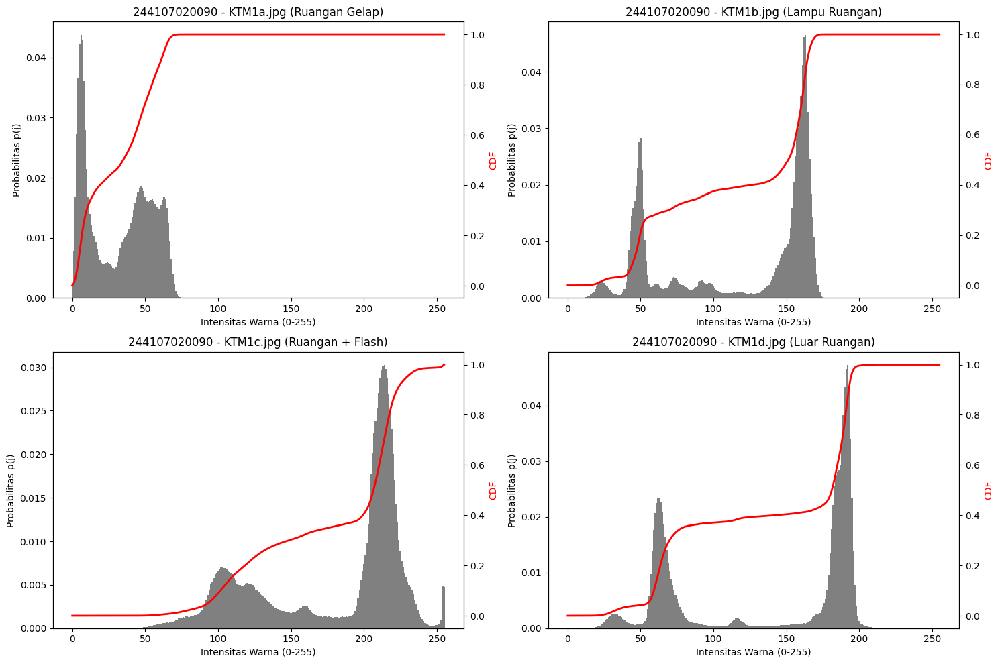

In [7]:
ktm_files = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
judul_kondisi = ['Ruangan Gelap', 'Lampu Ruangan', 'Ruangan + Flash', 'Luar Ruangan']

# Membuat Canvas 2x2
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, (file, kondisi) in enumerate(zip(ktm_files, judul_kondisi)):
    # Membaca Citra Dalam Format Grayscale
    img = cv.imread(BASE_PATH + file, cv.IMREAD_GRAYSCALE)

    # Menghitung Histogram
    hist, bins = np.histogram(img.flatten(), 256, [0, 256])

    # Normalisasi Histogram Menjadi Probabilitas p(j) (Total Jumlah = 1)
    p_j = hist / img.size

    # Menghitung Cumulative Distribution Function (CDF)
    cdf = np.cumsum(p_j)

    ax_hist = axes[i]
    ax_cdf = ax_hist.twinx() # Membuat Sumbu Y Kedua (Di Sebelah Kanan) Khusus Untuk CDF
    ax_hist.bar(bins[:-1], p_j, color='gray', width=1, label='p(j)')

    ax_cdf.plot(cdf, color='red', linewidth=2, label='CDF')

    ax_hist.set_title(f"244107020090 - {file} ({kondisi})")
    ax_hist.set_xlabel('Intensitas Warna (0-255)')
    ax_hist.set_ylabel('Probabilitas p(j)')
    ax_cdf.set_ylabel('CDF', color='red')

plt.tight_layout()
plt.show()

Berdasarkan hasil di atas, terdapat perbedaan signifikan pada bentuk kurva CDF. Pada citra paling gelap (KTM1a), kurva CDF menanjak di sisi kiri dan dengan cepat mencapai angka 1. Hal ini sesuai dengan kondisi pencahayaan saat akuisisi di mana cahaya gelap membuat mayoritas piksel bernilai mendekati 0. Sedangkan pada citra dengan pencahayaan paling bagus cahaya matahari (KTM1d), kurva CDF di sisi kiri landai dan baru naik secara signifikan di sisi kanan membuktikan tingginya eksposur cahaya matahari pada sensor kamera.

3. Pengurangan Jumlah Bin (Kuantisasi Histogram)

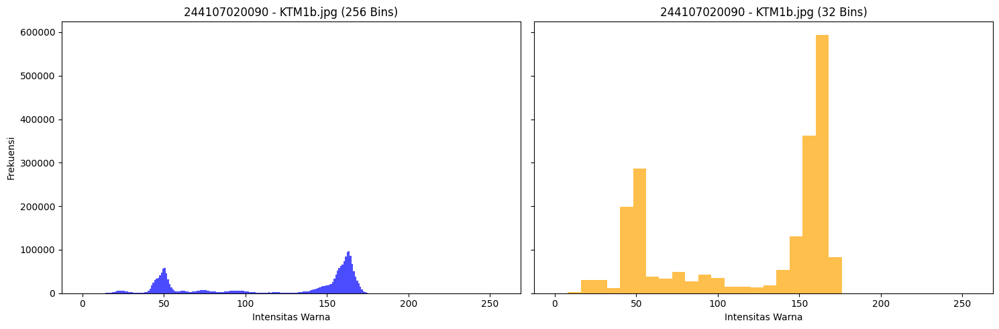

In [8]:
# Membaca Citra KTM1b.jpg Dalam Format Grayscale
img_ktm1b = cv.imread(BASE_PATH + 'KTM1b.jpg', cv.IMREAD_GRAYSCALE)

jumlah_bins_param = PARAM['bins']

fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# 1: Histogram Standar Menggunakan 256 Bins
axs[0].hist(img_ktm1b.flatten(), bins=256, range=[0, 256], color='blue', alpha=0.7)
axs[0].set_title('244107020090 - KTM1b.jpg (256 Bins)')
axs[0].set_xlabel('Intensitas Warna')
axs[0].set_ylabel('Frekuensi')

# 2: Histogram Menggunakan Jumlah Bins Berdasarkan NIM (32 Bins)
axs[1].hist(img_ktm1b.flatten(), bins=jumlah_bins_param, range=[0, 256], color='orange', alpha=0.7)
axs[1].set_title(f'244107020090 - KTM1b.jpg ({jumlah_bins_param} Bins)')
axs[1].set_xlabel('Intensitas Warna')

plt.tight_layout()
plt.show()

Ketika jumlah bin dikurangi dari 256 menjadi 32, beberapa informasi yang hilang adalah detail variasi kecil. Beberapa level intensitas yang berbeda dipaksa digabung dan diakumulasikan ke dalam satu rentang bin yang sama. Sehingga akibatnya adalah grafik terlihat sederhana, tetapi kehilangan kemampuan untuk melihat fluktuasi kecil, puncak puncak spesifik, atau perbedaan gradasi warna bayangan.

### E2 - Percobaan Histogram Equalization

Tahap 1

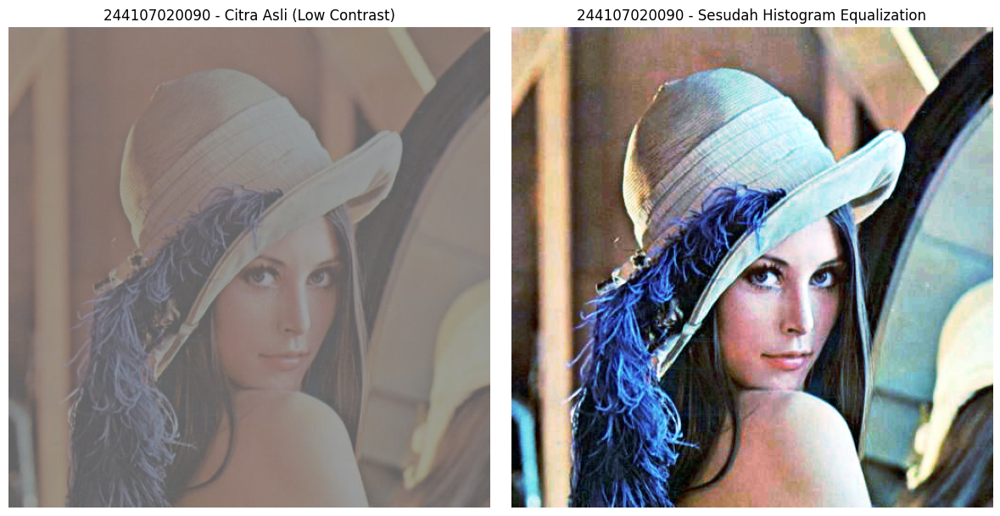

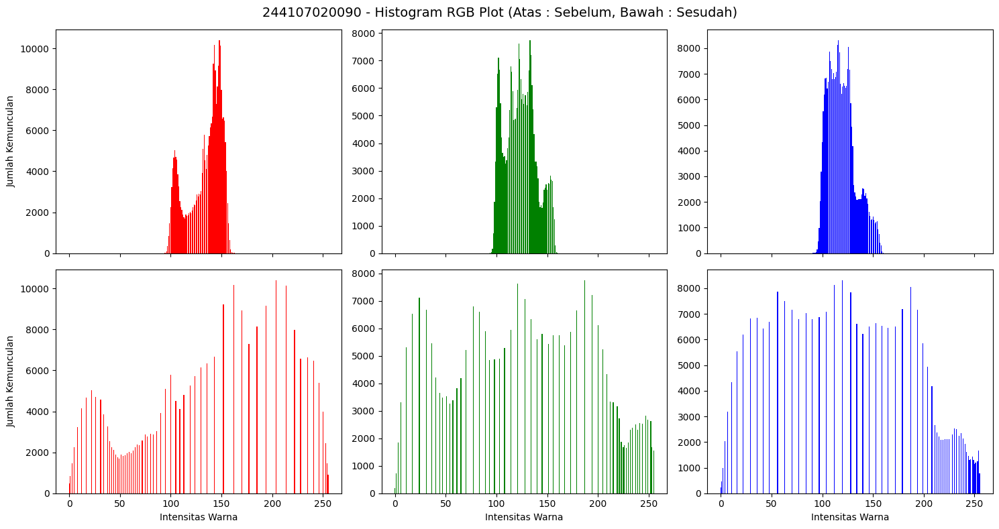

In [9]:
# Histogram Equalization
def equalization_manual(img):
    if len(img.shape) == 3:
        # Memisahkan Channel
        channels = cv.split(img)
        eq_channels = []

        # Melakukan Proses Equalization Untuk Setiap Channel Secara Terpisah
        for ch in channels:
            total_pixels = ch.size

            # 1. Menghitung Jumlah Kemunculan Setiap Piksel (Frekuensi)
            hist, _ = np.histogram(ch.flatten(), 256, [0, 256])

            # 2. Penjumlahan Kumulatif Dari Frekuensi
            cdf = hist.cumsum()

            # 3 & 4. Normalisasi Kumulatif Dan Implementasi Rumus Skala Warna (0-255) Serta Pembulatan
            map_warna = np.round((cdf / total_pixels) * 255).astype(np.uint8)

            # 5. Transformasi Kembali Nilai Piksel Lama Ke Dalam Bentuk Citra Baru Menggunakan Mapping
            eq_ch = map_warna[ch]
            eq_channels.append(eq_ch)

        # Menggabungkan Kembali Channel Yang Sudah Di-equalize Menjadi Citra RGB Utuh
        return cv.merge(eq_channels)

    else:
        # Jika Citra Berupa Grayscale (Hanya 1 Channel), Proses Langsung Dilakukan
        total_pixels = img.size
        hist, _ = np.histogram(img.flatten(), 256, [0, 256])
        cdf = hist.cumsum()
        map_warna = np.round((cdf / total_pixels) * 255).astype(np.uint8)
        return map_warna[img]

img_lena_lc = cv.imread(BASE_PATH + 'lena_lc.jpg')
img_lena_lc = cv.cvtColor(img_lena_lc, cv.COLOR_BGR2RGB)

# Menerapkan Fungsi Histogram Equalization Manual
img_lena_eq = equalization_manual(img_lena_lc)

fig_img, ax_img = plt.subplots(1, 2, figsize=(12, 6))

ax_img[0].imshow(img_lena_lc)
ax_img[0].set_title('244107020090 - Citra Asli (Low Contrast)')
ax_img[0].axis('off')

ax_img[1].imshow(img_lena_eq)
ax_img[1].set_title('244107020090 - Sesudah Histogram Equalization')
ax_img[1].axis('off')

plt.tight_layout()
plt.show()

fig_hist, ax_hist = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
fig_hist.suptitle('244107020090 - Histogram RGB Plot (Atas : Sebelum, Bawah : Sesudah)', fontsize=14)

warna = ['red', 'green', 'blue']
for i, col in enumerate(warna):
    # Histogram Sebelum
    hist_sebelum, _ = np.histogram(img_lena_lc[:, :, i].flatten(), 256, [0, 256])
    ax_hist[0, i].bar(np.arange(256), hist_sebelum, color=col)

    # Histogram Sesudah
    hist_sesudah, _ = np.histogram(img_lena_eq[:, :, i].flatten(), 256, [0, 256])
    ax_hist[1, i].bar(np.arange(256), hist_sesudah, color=col)

    if i == 0:
        ax_hist[0, i].set_ylabel('Jumlah Kemunculan')
        ax_hist[1, i].set_ylabel('Jumlah Kemunculan')
    ax_hist[1, i].set_xlabel('Intensitas Warna')

plt.tight_layout()
plt.show()

Dari hasil histogram tersebut sangat terlihat, bahwa histogram equalization akan menyebarkan nilai intensitas warna, sehingga akan meningkatkan kontras. Nilai intensitas yang sangat sering muncul di dalam gambar akan direnggangkan jaraknya, sedangkan nilai intensitas yang jarang muncul akan dirapatkan. Teknik ini efektif untuk memperbaiki gambar yang kusam, backlight, terlalu gelap, atau terlalu terang akibat rentang intensitas yang sempit.

Tahap 2

Selisih Maksimum Manual Vs OpenCV Pada lena_lc.jpg  : 0
Selisih Maksimum Manual Vs OpenCV Pada KTM1a.jpg    : 19


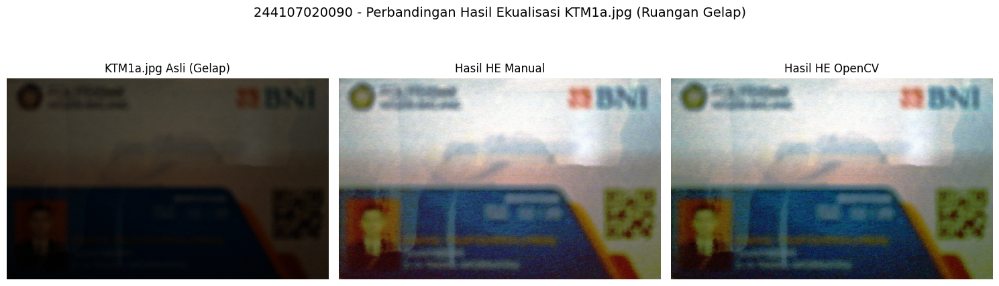

In [10]:
img_lena = cv.imread(BASE_PATH + 'lena_lc.jpg')
img_lena = cv.cvtColor(img_lena, cv.COLOR_BGR2RGB)

img_ktm1a = cv.imread(BASE_PATH + 'KTM1a.jpg')
img_ktm1a = cv.cvtColor(img_ktm1a, cv.COLOR_BGR2RGB)

# Fungsi Untuk Membandingkan Hasil HE Manual Dengan HE OpenCV
def bandingkan_he(img, nama_file):
    # 1. Histogram Equalization Manual
    he_manual = equalization_manual(img)

    # 2. Histogram Equalization OpenCV
    r, g, b = cv.split(img)

    # Melakukan Equalize Pada Masing-Masing Channel Menggunakan OpenCV
    r_eq = cv.equalizeHist(r)
    g_eq = cv.equalizeHist(g)
    b_eq = cv.equalizeHist(b)

    # Menggabungkan Kembali Channel Yang Sudah Di-equalize
    he_cv2 = cv.merge((r_eq, g_eq, b_eq))

    # 3. Menghitung Selisih Maksimum Antara Manual Dan OpenCV
    # Mengubah Tipe Data Ke int16 Agar Tidak Terpotong (Underflow) Saat Pengurangan Nilai Piksel
    selisih = np.max(np.abs(he_manual.astype(np.int16) - he_cv2.astype(np.int16)))

    print(f"Selisih Maksimum Manual Vs OpenCV Pada {nama_file:<12} : {selisih}")

    return he_manual, he_cv2

lena_manual, lena_cv2 = bandingkan_he(img_lena, 'lena_lc.jpg')
ktm_manual, ktm_cv2 = bandingkan_he(img_ktm1a, 'KTM1a.jpg')

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('244107020090 - Perbandingan Hasil Ekualisasi KTM1a.jpg (Ruangan Gelap)', fontsize=14)

ax[0].imshow(img_ktm1a)
ax[0].set_title('KTM1a.jpg Asli (Gelap)')
ax[0].axis('off')

ax[1].imshow(ktm_manual)
ax[1].set_title('Hasil HE Manual')
ax[1].axis('off')

ax[2].imshow(ktm_cv2)
ax[2].set_title('Hasil HE OpenCV')
ax[2].axis('off')

plt.tight_layout()
plt.show()

Perhitungan ekualisasi histogram manual dengan fungsi bawaan OpenCV tidak memiliki perbedaan pada citra lena_lc. Namun terdapat selisih sebesar 19 pada citra KTM1a. Hal ini terjadi karena OpenCV menggunakan rumus yang mengurangkan probabilitas kumulatif minimum pada pembilangnya agar nilai piksel tergelap benar-benar dipaksa menyentuh angka 0. Sedangkan algoritma manual membaginya secara merata berdasarkan total piksel. Secara visual, kedua hasil ekualisasi terlihat identik dan sama sama berhasil mencerahkan citra KTM yang sangat gelap. Akan tetapi, karena proses ekualisasi global ini diterapkan secara terpisah pada setiap channel warna (R, G, B). Sehingga foto menjadi pudar dan noise pada area bayangan menjadi lebih terlihat, yang menyebabkan tekstur gambar menjadi seperti berbintik.   

Tahap 3

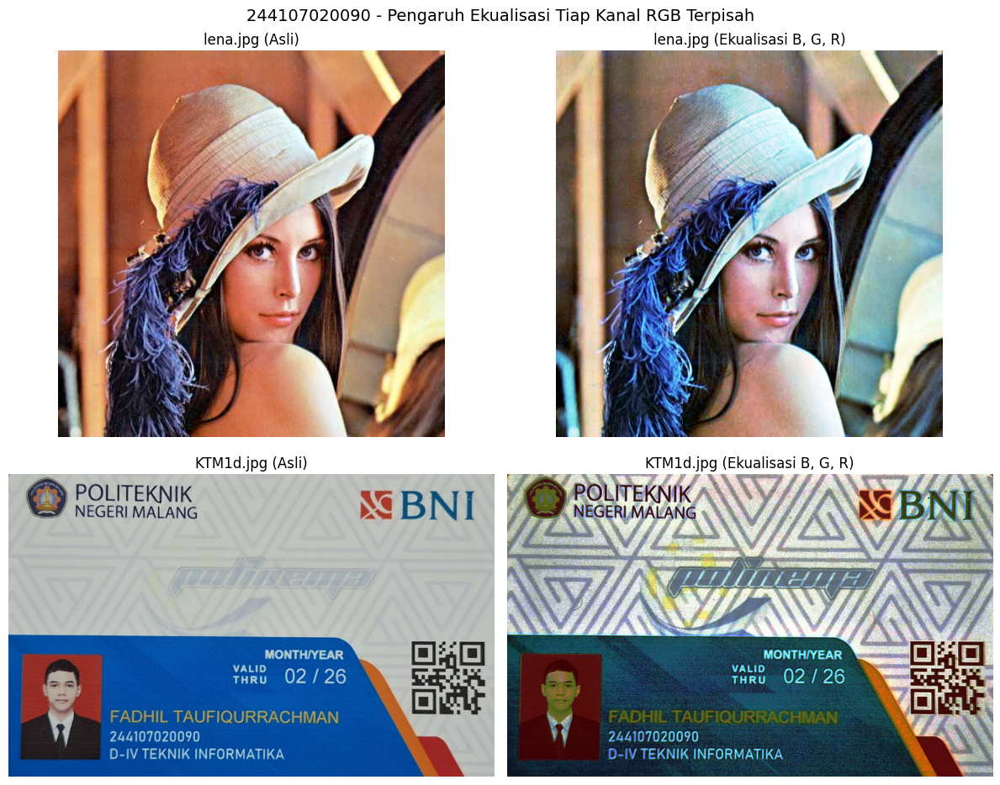

In [11]:
def ekualisasi_rgb_terpisah(nama_file):
    berkas = BASE_PATH + nama_file
    bgr = cv.imread(berkas)

    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)
    asli_rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    he_rgb_tampil = cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB)

    return asli_rgb, he_rgb_tampil, bgr, he_rgb

lena_asli, lena_he_tampil, _, _ = ekualisasi_rgb_terpisah('lena.jpg')
ktm_asli, ktm_he_tampil, ktm_bgr_asli, ktm_he_bgr = ekualisasi_rgb_terpisah('KTM1d.jpg')

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('244107020090 - Pengaruh Ekualisasi Tiap Kanal RGB Terpisah', fontsize=14)

ax[0, 0].imshow(lena_asli)
ax[0, 0].set_title('lena.jpg (Asli)')
ax[0, 0].axis('off')

ax[0, 1].imshow(lena_he_tampil)
ax[0, 1].set_title('lena.jpg (Ekualisasi B, G, R)')
ax[0, 1].axis('off')

ax[1, 0].imshow(ktm_asli)
ax[1, 0].set_title('KTM1d.jpg (Asli)')
ax[1, 0].axis('off')

ax[1, 1].imshow(ktm_he_tampil)
ax[1, 1].set_title('KTM1d.jpg (Ekualisasi B, G, R)')
ax[1, 1].axis('off')

plt.tight_layout()
plt.show()

Warna pada citra lena dan KTM1d terlihat memudar dan mengalami distorsi yang signifikan setelah proses ekualisasi. Hal ini terjadi karena proses ekualisasi diterapkan secara terpisah pada masing-masing channel. Ekualisasi memaksakan penyebaran intensitas piksel di setiap channel, sehingga merusak perbandingan komposisi asli dari ketiga warna dasar tersebut. Karena persepsi warna yang kita lihat sangat bergantung pada proporsi RGB yang spesifik, rusaknya rasio ini membuat warna asli objek bergeser secara acak. Eksperimen ini membuktikan bahwa mengekualisasi gambar berwarna RGB secara langsung sangat tidak disarankan.

Tahap 4

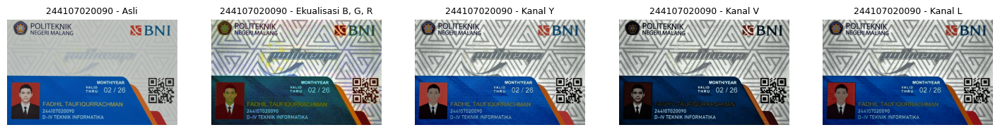

Cara                         Geser Hue (der)      Rerata Terang
Asli                                    0.00              138.8
Ekualisasi B, G, R                     37.39              127.7
Kanal Y                                 1.28              131.6
Kanal V                                 2.86              115.9
Kanal L                                 7.20              123.1

Pergeseran Hue CLAHE: 0.10338225017470301
Rerata Kecerahan CLAHE: 140.63306016136204
(clipLimit=1.0, tileGridSize=(4,4))


In [16]:
bgr = cv.imread(BASE_PATH + 'KTM1d.jpg')

kanal = list(cv.split(bgr))
for i in range(3):
    kanal[i] = cv.equalizeHist(kanal[i])
he_rgb = cv.merge(kanal)

# 1. Ruang Warna YCrCb
ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)
he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

# 2. Ruang Warna HSV
hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
h, sat, v = cv.split(hsv)
he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

# 3. Ruang Warna LAB
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b = cv.split(lab)
he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

# --- Visualisasi
judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
citra = [bgr, he_rgb, he_y, he_v, he_l]

plt.figure(figsize=(18, 4))
for i, (c, t) in enumerate(zip(citra, judul), 1):
    plt.subplot(1, 5, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title('244107020090 - ' + t, fontsize=9)
    plt.axis('off')
plt.show()

# Hue Pada OpenCV Bersifat Melingkar (0-179), Selisih Dihitung Lewat Jalur Terpendek
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)
    return d.mean()

print('%-25s %18s %18s' % ('Cara', 'Geser Hue (der)', 'Rerata Terang'))
for t, c in zip(judul, citra):
    print('%-25s %18.2f %18.1f' % (t, geser_hue(bgr, c) * 2, cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))

clip_limit = PARAM['clip']
tile_size = PARAM['tile']
clahe = cv.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile_size, tile_size))

# Menerapkan CLAHE pada kanal Y
y_clahe = clahe.apply(y)
he_clahe = cv.cvtColor(cv.merge([y_clahe, cr, cb]), cv.COLOR_YCrCb2BGR)

# Menghitung pergeseran hue dan rerata kecerahan untuk CLAHE
hue_clahe = geser_hue(bgr, he_clahe) * 2
terang_clahe = cv.cvtColor(he_clahe, cv.COLOR_BGR2GRAY).mean()

print(f"\nPergeseran Hue CLAHE: {hue_clahe}")
print(f"Rerata Kecerahan CLAHE: {terang_clahe}")
print(f"(clipLimit={clip_limit}, tileGridSize=({tile_size},{tile_size}))")

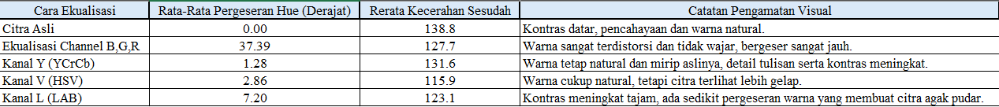

1. Cara yang menghasilkan pergeseran Hue paling besar adalah Ekualisasi kanal B, G, R secara terpisah, dengan nilai pergeseran sebesar 37.39 derajat pada citra KTM1d.


2. Ekualisasi pada channel terang tetap menghasilkan pergeseran Hue meskipun kecil, karena saat ruang warna (YCrCb) dikonversi kembali ke ruang warna RGB/BGR di akhir proses, terjadi perhitungan desimal. Karena citra digital harus disimpan dalam format 8-bit, nilai desimal ini harus dibulatkan ke bilangan bulat terdekat dan diclipping agar tidak melebihi rentang 0-255. Proses pembulatan paksa inilah yang menyebabkan komposisi warna asli bergeser dan berubah.


3. Channel Y (YCrCb) yang paling sesuai untuk foto KTM. Hal ini dikarenakan channel Y memiliki pergeseran Hue paling kecil (hanya 1.28 derajat) sehingga warnanya paling utuh dipertahankan. Secara visual juga lebih mendekati versi aslinya dibandingkan yang lain.


4. Berdasarkan uji coba CLAHE dengan parameter clipLimit=1.0 dan tileGridSize=(4,4), pergeseran Hue turun drastis dan menjadi hanya 0.10 derajat, lebih stabil dibandingkan ekualisasi biasa di channel Y (1.28 derajat). Selain itu, rerata kecerahan dengan CLAHE adalah 140.6, yang paling mendekati tingkat kecerahan natural citra asli (138.8) dibandingkan dengan ekualisasi global biasa (131.6). Hal ini membuktikan bahwa CLAHE mampu meratakan kontras secara lokal tanpa merusak pencahayaan global dan warna citra.

**Pertanyaan Praktikum E2**

1. Ekualisasi Global Citra KTM

Nilai PSNR (Asli vs Manual) : 7.27 dB
Nilai PSNR (Asli vs OpenCV) : 7.28 dB



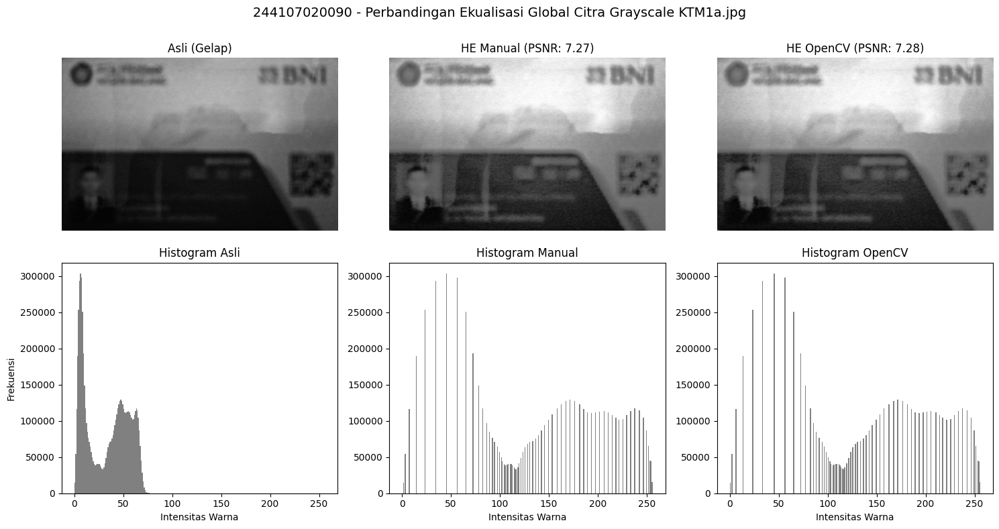

In [18]:
img_ktm_gray = cv.imread(BASE_PATH + 'KTM1a.jpg', cv.IMREAD_GRAYSCALE)

# Menerapkan Ekualisasi Manual Dan cv.equalizeHist
ktm_gray_manual = equalization_manual(img_ktm_gray)
ktm_gray_cv2 = cv.equalizeHist(img_ktm_gray)

# Menghitung Nilai PSNR Antara Citra Asli Dan Hasil Ekualisasi (Bawaan OpenCV)
psnr_manual = cv.PSNR(img_ktm_gray, ktm_gray_manual)
psnr_cv2 = cv.PSNR(img_ktm_gray, ktm_gray_cv2)

print(f"Nilai PSNR (Asli vs Manual) : {psnr_manual:.2f} dB")
print(f"Nilai PSNR (Asli vs OpenCV) : {psnr_cv2:.2f} dB\n")

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('244107020090 - Perbandingan Ekualisasi Global Citra Grayscale KTM1a.jpg', fontsize=14)

# Citra
ax[0, 0].imshow(img_ktm_gray, cmap='gray')
ax[0, 0].set_title('Asli (Gelap)')
ax[0, 0].axis('off')

ax[0, 1].imshow(ktm_gray_manual, cmap='gray')
ax[0, 1].set_title(f'HE Manual (PSNR: {psnr_manual:.2f})')
ax[0, 1].axis('off')

ax[0, 2].imshow(ktm_gray_cv2, cmap='gray')
ax[0, 2].set_title(f'HE OpenCV (PSNR: {psnr_cv2:.2f})')
ax[0, 2].axis('off')

# Histogram
ax[1, 0].hist(img_ktm_gray.flatten(), bins=256, range=[0,256], color='gray')
ax[1, 0].set_title('Histogram Asli')
ax[1, 0].set_xlabel('Intensitas Warna')
ax[1, 0].set_ylabel('Frekuensi')

ax[1, 1].hist(ktm_gray_manual.flatten(), bins=256, range=[0,256], color='gray')
ax[1, 1].set_title('Histogram Manual')
ax[1, 1].set_xlabel('Intensitas Warna')

ax[1, 2].hist(ktm_gray_cv2.flatten(), bins=256, range=[0,256], color='gray')
ax[1, 2].set_title('Histogram OpenCV')
ax[1, 2].set_xlabel('Intensitas Warna')

plt.tight_layout()
plt.show()

Nilai PSNR menurun drastis ke angka yang sangat rendah yaitu 7.27 dB untuk perhitungan manual dan 7.28 dB untuk OpenCV, berbanding terbalik dengan detail tulisan pada kartu yang justru jauh lebih jelas terbaca. Penurunan ini terjadi karena PSNR mengukur selisih MSE antara piksel citra awal yang gelap dengan citra hasil manipulasi yang terang. Oleh karena itu, PSNR sama sekali tidak bagus jika digunakan untuk menilai keberhasilan perbaikan kontras (enhancement) pada sebuah citra. PSNR hanya mengukur seberapa identik citra dipertahankan, bukan menilai seberapa jelas informasi visual yang dapat dilihat.

2. Ekualisasi Lokal Dengan CLAHE Citra KTM

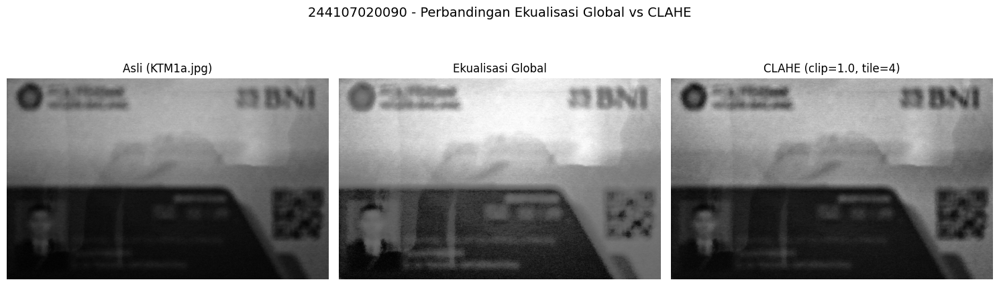

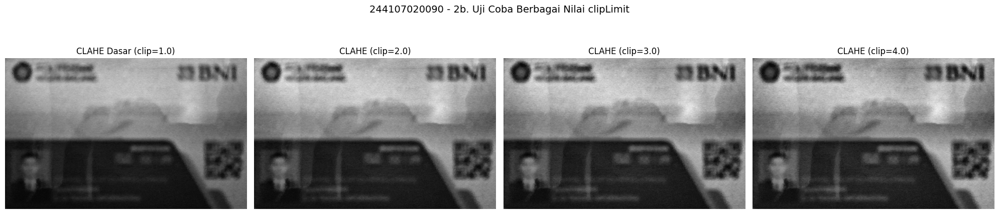

In [21]:
clip_param = PARAM['clip']
tile_param = PARAM['tile']

img_ktm_gray = cv.imread(BASE_PATH + 'KTM1a.jpg', cv.IMREAD_GRAYSCALE)

ktm_gray_global = cv.equalizeHist(img_ktm_gray)

clahe_nim = cv.createCLAHE(clipLimit=clip_param, tileGridSize=(tile_param, tile_param))
ktm_clahe_nim = clahe_nim.apply(img_ktm_gray)

clip_uji = [0.5, 2.0, 3.0]
hasil_clahe_uji = []
for c in clip_uji:
    clahe_uji = cv.createCLAHE(clipLimit=c, tileGridSize=(tile_param, tile_param))
    hasil_clahe_uji.append(clahe_uji.apply(img_ktm_gray))

fig1, ax1 = plt.subplots(1, 3, figsize=(15, 5))
fig1.suptitle('244107020090 - Perbandingan Ekualisasi Global vs CLAHE', fontsize=14)

ax1[0].imshow(img_ktm_gray, cmap='gray')
ax1[0].set_title('Asli (KTM1a.jpg)')
ax1[0].axis('off')

ax1[1].imshow(ktm_gray_global, cmap='gray')
ax1[1].set_title('Ekualisasi Global')
ax1[1].axis('off')

ax1[2].imshow(ktm_clahe_nim, cmap='gray')
ax1[2].set_title(f'CLAHE (clip={clip_param}, tile={tile_param})')
ax1[2].axis('off')

plt.tight_layout()
plt.show()

clip_uji = [2.0, 3.0, 4.0]
hasil_clahe_uji = []
for c in clip_uji:
    clahe_uji = cv.createCLAHE(clipLimit=c, tileGridSize=(tile_param, tile_param))
    hasil_clahe_uji.append(clahe_uji.apply(img_ktm_gray))

fig2, ax2 = plt.subplots(1, 4, figsize=(20, 5))
fig2.suptitle('244107020090 - 2b. Uji Coba Berbagai Nilai clipLimit', fontsize=14)

ax2[0].imshow(ktm_clahe_nim, cmap='gray')
ax2[0].set_title(f'CLAHE Dasar (clip={clip_param})')
ax2[0].axis('off')

for i, hasil in enumerate(hasil_clahe_uji):
    ax2[i+1].imshow(hasil, cmap='gray')
    ax2[i+1].set_title(f'CLAHE (clip={clip_uji[i]})')
    ax2[i+1].axis('off')

plt.tight_layout()
plt.show()

a. Nama dan NIM pada kartu jauh lebih jelas dan mudah terbaca pada hasil CLAHE dibandingkan dengan Ekualisasi Global. Ekualisasi global meratakan kontras secara keseluruhan yang menyebabkan area latar belakang menjadi terlalu putih (overexposed) dan noise secara otomatis ikut diperjelas, sehingga detail huruf justru tampak memudar dan berbayang. Sebaliknya, CLAHE memproses citra per petak kecil secara lokal, sehingga mampu meningkatkan ketajaman kontras pada teks tanpa merusak tingkat kecerahan area di sekitarnya

b. Setelah melakukan uji coba, nilai terbaik untuk citra KTM adalah 1.0 (CLAHE Dasar). Pada nilai 1.0, kontras teks meningkat sehingga lebih mudah terbaca, namun tekstur gambar masih terjaga dengan baik. Ketika nilai clipLimit terus dinaikkan dari 2.0 hingga puncaknya di 4.0, noise atau bintik-bintik kasar menjadi semakin jelas dan sangat mengganggu visual. Peningkatan noise yang merusak paling terlihat jelas pada area yang bergradasi halus, yaitu di bagian latar belakang terang pada setengah area atas kartu serta pada area bayangan gelap di sekitar teks dan foto.

### E3 - Tugas Praktikum Dithering

1. Dithering Floyd-Steinberg

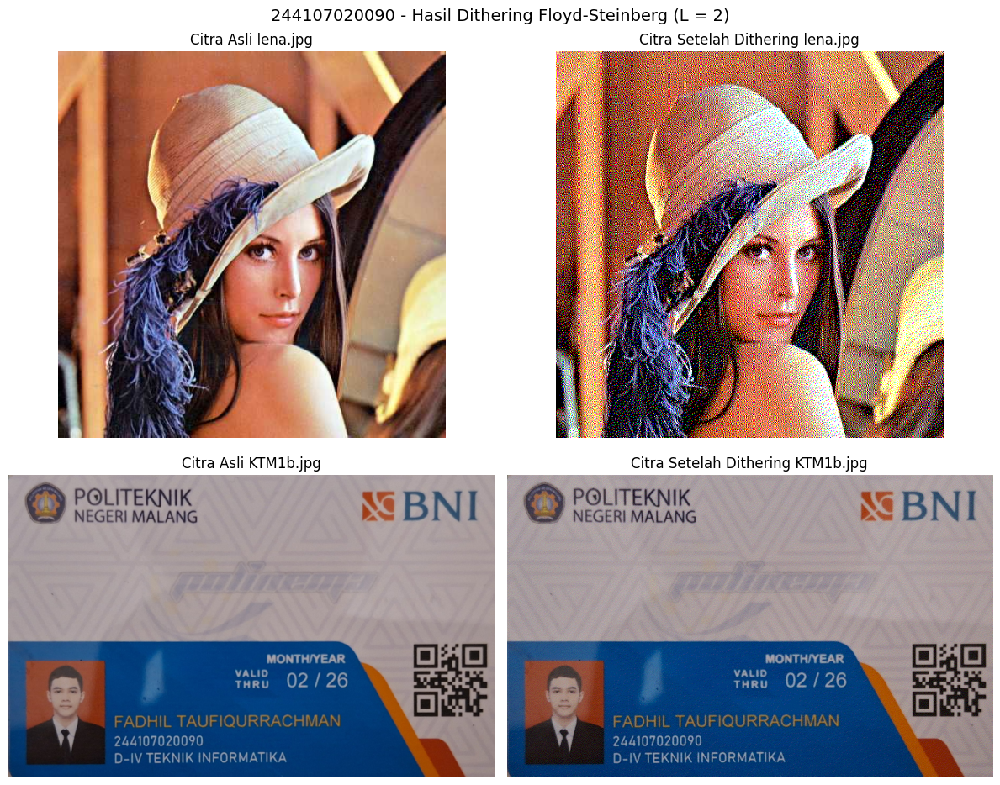

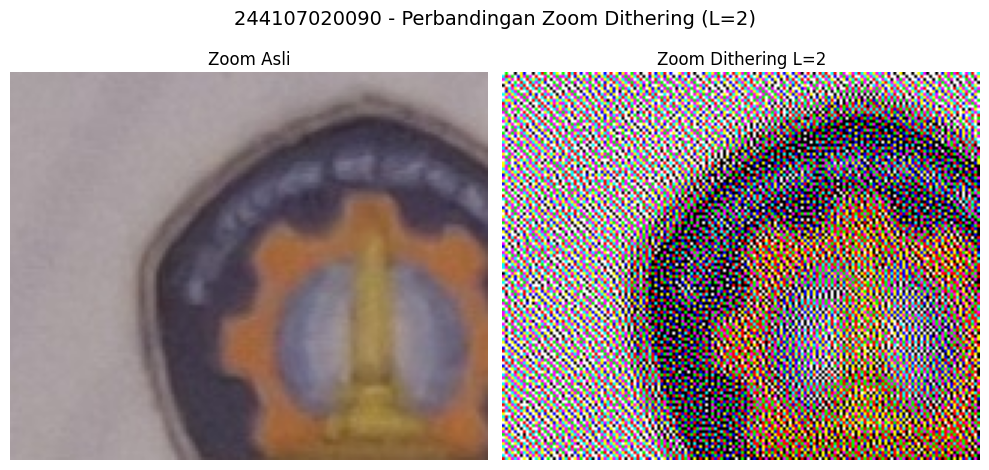

In [26]:
L_param = PARAM['L']

def floyd_steinberg_gray(gray, L):
    # Mengubah Tipe Data Ke float32 Serta Menduplikasi Array Agar Error Desimal Tidak Terpotong
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape
    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru
            if x + 1 < W:
                img[y, x + 1] += error * (7.0 / 16.0)
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * (3.0 / 16.0)
            if y + 1 < H:
                img[y + 1, x] += error * (5.0 / 16.0)
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * (1.0 / 16.0)
    return np.clip(img, 0, 255).astype(np.uint8)

def floyd_steinberg_color(img_bgr, L):
    b, g, r = cv.split(img_bgr)
    b_dith = floyd_steinberg_gray(b, L)
    g_dith = floyd_steinberg_gray(g, L)
    r_dith = floyd_steinberg_gray(r, L)
    # Menggabungkan Kembali Ketiga Kanal Menjadi Citra Utuh
    return cv.merge((b_dith, g_dith, r_dith))

img_lena_asli = cv.imread(BASE_PATH + 'lena.jpg')
lena_dithered = floyd_steinberg_color(img_lena_asli, 2)
img_ktm_asli = cv.imread(BASE_PATH + 'KTM1b.jpg')
ktm_dithered = floyd_steinberg_color(img_ktm_asli, L_param)
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle(f'244107020090 - Hasil Dithering Floyd-Steinberg (L = {L_param})', fontsize=14)

ax[0, 0].imshow(cv.cvtColor(img_lena_asli, cv.COLOR_BGR2RGB))
ax[0, 0].set_title('Citra Asli lena.jpg')
ax[0, 0].axis('off')

ax[0, 1].imshow(cv.cvtColor(lena_dithered, cv.COLOR_BGR2RGB))
ax[0, 1].set_title('Citra Setelah Dithering lena.jpg')
ax[0, 1].axis('off')

ax[1, 0].imshow(cv.cvtColor(img_ktm_asli, cv.COLOR_BGR2RGB))
ax[1, 0].set_title('Citra Asli KTM1b.jpg')
ax[1, 0].axis('off')

ax[1, 1].imshow(cv.cvtColor(ktm_dithered, cv.COLOR_BGR2RGB))
ax[1, 1].set_title(f'Citra Setelah Dithering KTM1b.jpg')
ax[1, 1].axis('off')

plt.tight_layout()
plt.show()

y_start, y_end = 20, 150
x_start, x_end = 20, 180

zoom_asli = img_ktm_asli[y_start:y_end, x_start:x_end]
zoom_dithering = ktm_dithered[y_start:y_end, x_start:x_end]

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle(f'244107020090 - Perbandingan Zoom Dithering (L={L_param})', fontsize=14)

ax[0].imshow(cv.cvtColor(zoom_asli, cv.COLOR_BGR2RGB))
ax[0].set_title('Zoom Asli')
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(zoom_dithering, cv.COLOR_BGR2RGB))
ax[1].set_title(f'Zoom Dithering L={L_param}')
ax[1].axis('off')

plt.tight_layout()
plt.show()

Berdasarkan perbandingan tersebut, perbedaan wujud citra asli dan hasil dithering terlihat sangat mencolok. Meskipun dalam ukuran normal keduanya tampak serupa akibat ilusi optik perpaduan visual oleh mata manusia, pada perbesaran tampak jelas bahwa citra dithering sebenarnya tersusun dari pola titik titik piksel kasar yang tersebar secara acak. Pola titik ini muncul karena algoritma Floyd-Steinberg memangkas jumlah kedalaman warna secara drastis dan mendistribusikan sisa error ke piksel-piksel tetangganya, yang merupakan sebuah teknik manipulasi untuk tetap mempertahankan kesan gradasi warna yang halus meskipun menggunakan warna yang sangat terbatas.

2. Grayscale Dithering

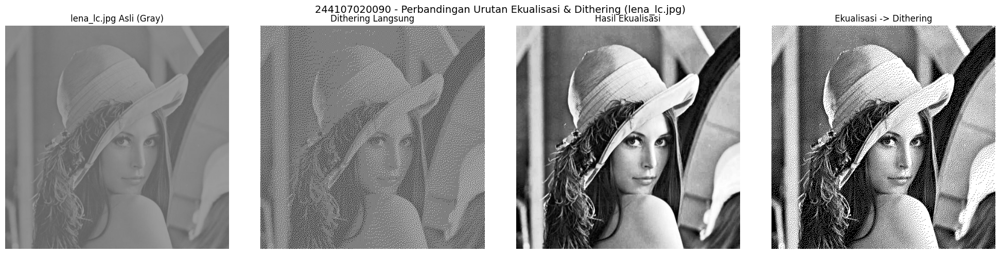

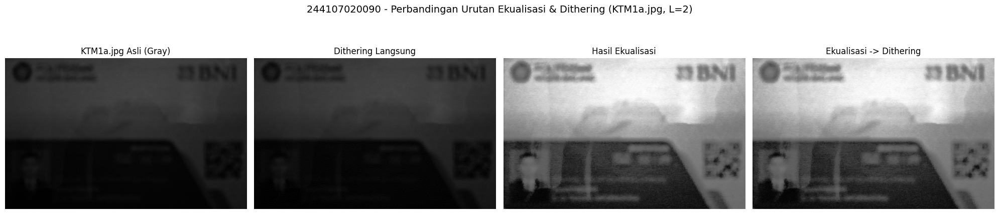

In [29]:
def proses_dan_bandingkan(nama_file, L, judul_utama):
    img_gray = cv.imread(BASE_PATH + nama_file, cv.IMREAD_GRAYSCALE)
    dither_langsung = floyd_steinberg_gray(img_gray, L)
    img_eq = cv.equalizeHist(img_gray)
    eq_lalu_dither = floyd_steinberg_gray(img_eq, L)

    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(judul_utama, fontsize=14)

    ax[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
    ax[0].set_title(f'{nama_file} Asli (Gray)')
    ax[0].axis('off')

    ax[1].imshow(dither_langsung, cmap='gray', vmin=0, vmax=255)
    ax[1].set_title('Dithering Langsung')
    ax[1].axis('off')

    ax[2].imshow(img_eq, cmap='gray', vmin=0, vmax=255)
    ax[2].set_title('Hasil Ekualisasi')
    ax[2].axis('off')

    ax[3].imshow(eq_lalu_dither, cmap='gray', vmin=0, vmax=255)
    ax[3].set_title('Ekualisasi -> Dithering')
    ax[3].axis('off')

    plt.tight_layout()
    plt.show()

proses_dan_bandingkan('lena_lc.jpg', 2, '244107020090 - Perbandingan Urutan Ekualisasi & Dithering (lena_lc.jpg)')
proses_dan_bandingkan('KTM1a.jpg', L_param, f'244107020090 - Perbandingan Urutan Ekualisasi & Dithering (KTM1a.jpg, L={L_param})')

Urutan yang menghasilkan teks jauh lebih terbaca adalah Ekualisasi lalu Dithering. Citra KTM asli memiliki kondisi pencahayaan yang sangat gelap sehingga rentang intensitas pikselnya bertumpuk di nilai rendah. Jika dithering dikerjakan langsung, algoritma Floyd-Steinberg hanya akan memetakan piksel-piksel gelap tersebut ke level palet terendah dengan error yang minim tersebar, sehingga gambar tetap pekat dan teks tidak bisa dibaca. Sebaliknya, dengan melakukan ekualisasi terlebih dahulu, kontras gambar diregangkan dulu sehingga bentuk huruf terpisah jelas dari latar belakangnya. Setelah kontrasnya tajam, proses dithering dapat membentuk pola titik dengan jauh lebih jelas meskipun kedalaman warnanya telah diturunkan.